In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # practice/から見て一つ上がプロジェクトルート想定

from dotenv import load_dotenv
load_dotenv()

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from app.db.session import engine
from app.analysis.matching import load_analysis_data

df = load_analysis_data(engine)
df = df.dropna(subset=["area_group", "station_distance", "liv_area", "price"]).copy()
df.head(3)

,room_id,price,floor,liv_area,floor_plan,building_id,station_distance,age,total_floors,building_structure,building_type,brand_score,location_score,title,address,log_price,floor_plan_cat,building_type_cat,area_group
0,1944,260000,1.0,55.37,1LDK,389,6,22,6,RC,マンション,1.0,3.0,KDXレジデンス西原,東京都渋谷区西原1,12.468437,1LDK,マンション,東京都渋谷区西原
1,1946,310000,4.0,65.25,2LDK,389,6,22,6,RC,マンション,1.0,3.0,KDXレジデンス西原,東京都渋谷区西原1,12.644328,2K以上,マンション,東京都渋谷区西原
2,603,88000,2.0,19.82,ワンルーム,145,3,33,10,鉄骨,マンション,1.0,3.0,恵比寿アーバンハウス,東京都渋谷区恵比寿1,11.385092,1R,マンション,東京都渋谷区恵比寿
3,604,90000,2.0,19.82,ワンルーム,145,3,33,10,鉄骨,マンション,1.0,3.0,恵比寿アーバンハウス,東京都渋谷区恵比寿1,11.407565,1R,マンション,東京都渋谷区恵比寿
4,605,90000,3.0,19.82,ワンルーム,145,3,33,10,鉄骨,マンション,1.0,3.0,恵比寿アーバンハウス,東京都渋谷区恵比寿1,11.407565,1R,マンション,東京都渋谷区恵比寿


town_jp
代々木    364
本町     358
笹塚     251
恵比寿    231
広尾     182
幡ヶ谷    176
上原     134
千駄     134
富ヶ谷    110
初台     107
Name: count, dtype: int64


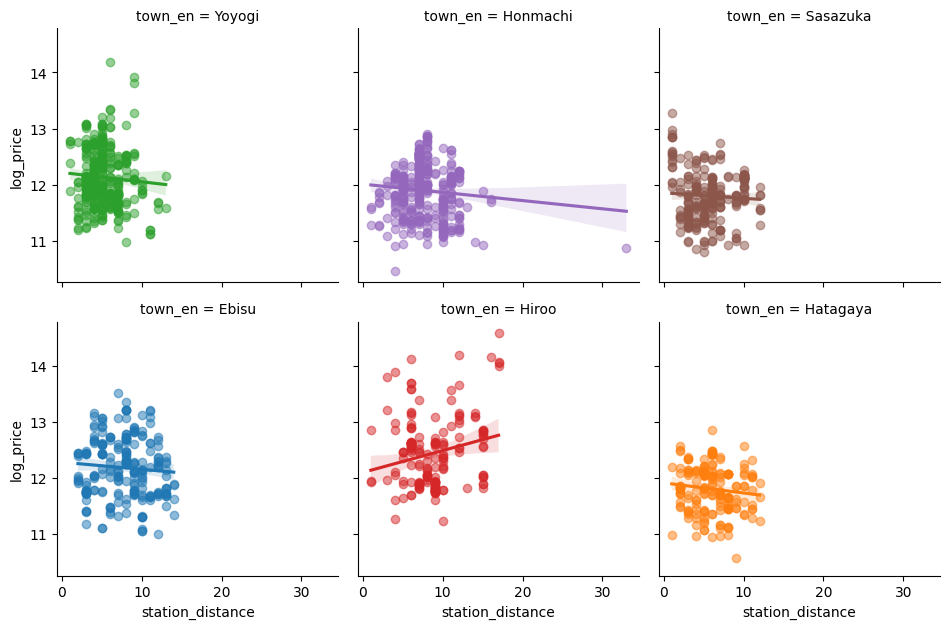

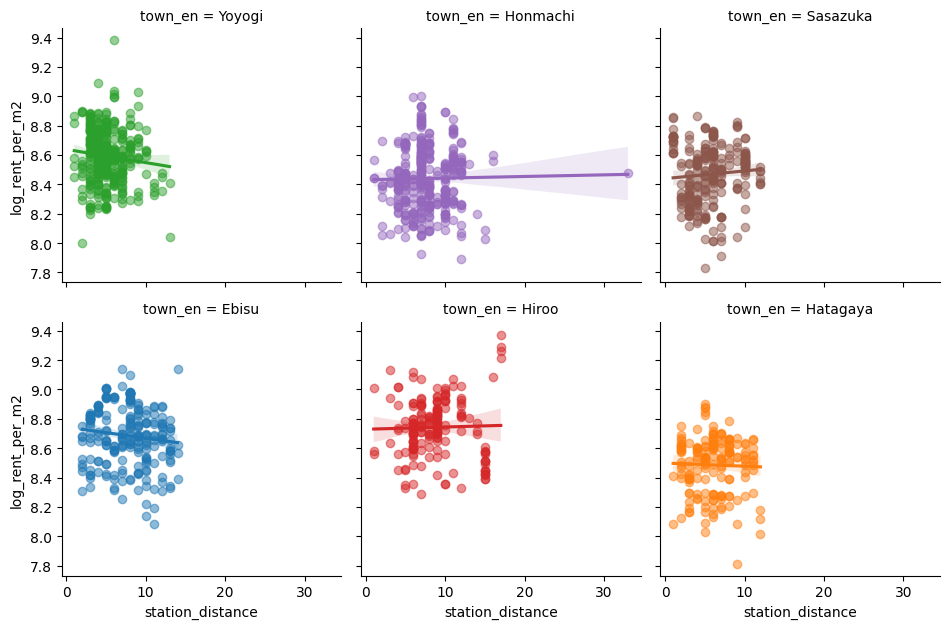

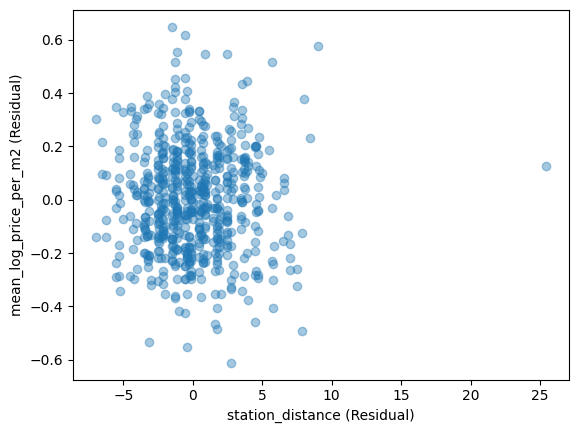

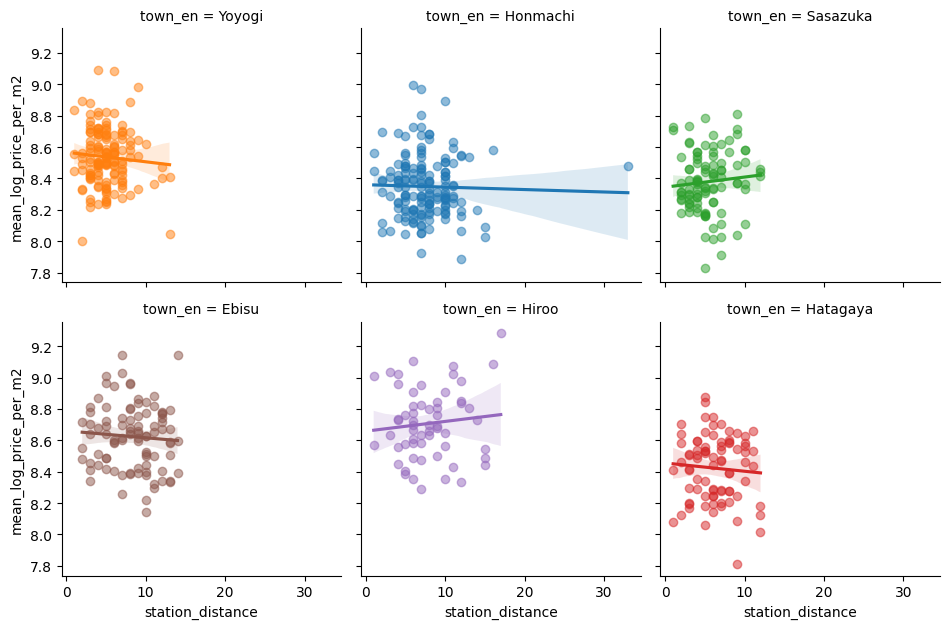

In [4]:

# log_priceはload_analysis_data内で既に計算済み

df["town_jp"] = df["area_group"].str.replace("東京都渋谷区", "", regex=False)

town_map_en = {
    "代々木": "Yoyogi", "本町": "Honmachi", "笹塚": "Sasazuka",
    "恵比寿": "Ebisu", "広尾": "Hiroo", "幡ヶ谷": "Hatagaya",
}
order_en = ["Yoyogi", "Honmachi", "Sasazuka", "Ebisu", "Hiroo", "Hatagaya"]

print(df["town_jp"].value_counts().head(10))
df["town_en"] = df["town_jp"].map(town_map_en)
df_top = df[df["town_en"].isin(order_en)].copy()
df_top["log_rent_per_m2"] = np.log(df_top["price"] / df_top["liv_area"])

# --- グラフ1・2（room単位） ---
g1 = sns.lmplot(data=df_top, x="station_distance", y="log_price",
                 hue="town_en", col="town_en", col_order=order_en, col_wrap=3,
                 height=3.2, scatter_kws={"alpha": 0.5})
g1.savefig("../docs/images/phase3_graph1.png", dpi=150, bbox_inches="tight")

g2 = sns.lmplot(data=df_top, x="station_distance", y="log_rent_per_m2",
                 hue="town_en", col="town_en", col_order=order_en, col_wrap=3,
                 height=3.2, scatter_kws={"alpha": 0.5})
g2.savefig("../docs/images/phase3_graph2.png", dpi=150, bbox_inches="tight")

# --- building単位集計 ---
df["log_price_per_m2"] = np.log(df["price"] / df["liv_area"])
agg_df = (
    df.groupby(["building_id", "station_distance"])
    .agg(mean_log_price_per_m2=("log_price_per_m2", "mean"), room_count=("room_id", "count"))
    .reset_index()
    .merge(df[["building_id", "town_en"]].drop_duplicates(), on="building_id")
)
agg_top = agg_df[agg_df["town_en"].isin(order_en)].copy()

# --- グラフ3（部分回帰プロット） ---
resid_x = smf.ols("station_distance ~ C(town_en)", data=agg_top).fit().resid
resid_y = smf.ols("mean_log_price_per_m2 ~ C(town_en)", data=agg_top).fit().resid
plt.figure()
plt.scatter(resid_x, resid_y, alpha=0.4)
plt.xlabel("station_distance (Residual)")
plt.ylabel("mean_log_price_per_m2 (Residual)")
plt.savefig("../docs/images/phase3_graph3.png", dpi=150, bbox_inches="tight")

# --- グラフ4（町別の傾き） ---
g4 = sns.lmplot(data=agg_top, x="station_distance", y="mean_log_price_per_m2",
                 hue="town_en", col="town_en", col_order=order_en, col_wrap=3,
                 height=3.2, scatter_kws={"alpha": 0.5})
g4.savefig("../docs/images/phase3_graph4.png", dpi=150, bbox_inches="tight")